# Practice lab solutions (TRAINER): Rohan's memo on German Credit

*The transfer paragraph and the error bill, run on a real lender's applicants. TA-led after the second block, then self-study. About 90 minutes; parts 1 to 4 and the write-up are the core 60.*

**The real situation.** German Credit (Statlog, Hans Hofmann) holds 1,000 loan applicants from Hamburg in 1994, and its own documentation states the cost matrix: approving a bad customer costs 5, turning away a good one costs 1. Zillow's 2021 write-down is the reminder that a forecast's bill arrives in both directions.

**The Kalpa twin.** Rohan Desai, head of risk at Kalpa Financial, sat on Monday's committee to learn what carries over. His costs are Rs 60,000 for a default approved and Rs 3,000 for a good applicant turned away. Build 2 next week starts from this memo.

**How it runs.** Each TODO cell runs as shipped and prints `TO DO` until you replace the `None`. The check under it prints PASS when your number is right.

## Who asks what of this model?

| Seat | Their question |
|---|---|
| Business owner (Rohan) | What does a wrong approval cost, and where is the line? |
| Product manager | What does an applicant experience when the model says no? |
| Solution architect | Where does the cut live, and who may change it? |
| Senior ML engineer | Is the probability honest enough to put a cut on? |
| Implementation engineer | What runs at the moment of approval, and what does it log? |
| QA | What breaks the result: a new cost, a small segment, a column that leaks? |

(1000, 21)
PASS  1,000 applicants loaded
PASS  the target holds only good and bad


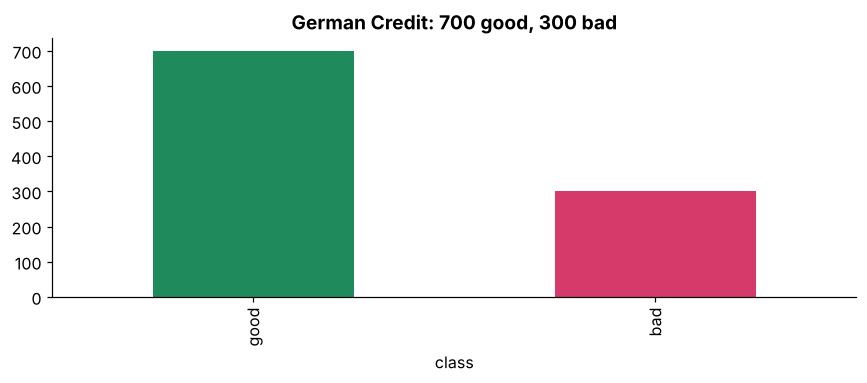

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)

import pathlib
import numpy as np, pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
credit = fetch_openml(name="credit-g", version=1, as_frame=True, data_home=str(CACHE / "openml")).frame
def mark(label, mine, right, tol=0.0):
    if mine is None:
        print("TO DO  " + label)
    else:
        check(label, abs(mine - right) <= tol)
print(credit.shape)
check("1,000 applicants loaded", len(credit) == 1000)
check("the target holds only good and bad", set(credit["class"]) == {"good", "bad"})
credit["class"].value_counts().plot.bar(color=[GREEN, ROSE], title="German Credit: 700 good, 300 bad"); plt.tight_layout(); plt.show()

## Part 1: what share of applicants repaid?

The positive class is now the good outcome. Compute the share of `class == "good"`.

In [2]:
base_rate = (credit["class"] == "good").mean()
print(round(base_rate, 3))

0.7


In [3]:
mark("base rate of good applicants", base_rate, 0.70, 0.001)

PASS  base rate of good applicants


## Part 2: where is the lending line at 5 : 1?

Approve when P(repay) is above `cost of the expensive mistake / (cheap + expensive)`, since the expensive mistake is approving a bad customer.

In [4]:
cut = 5 / (5 + 1)
print(round(cut, 3))

0.833


PASS  the 5 : 1 cut


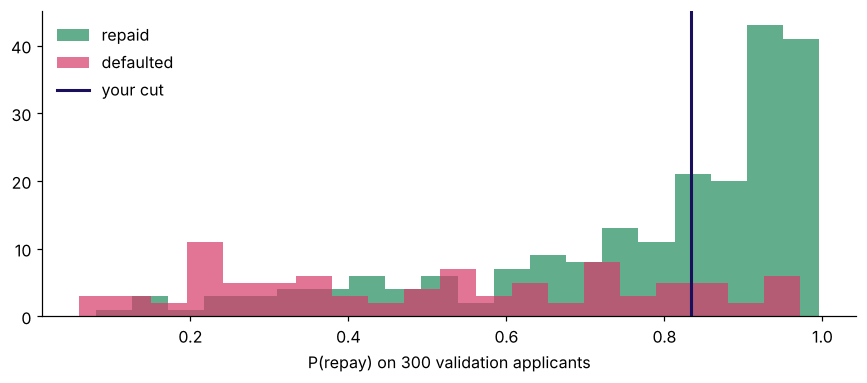

In [5]:
mark("the 5 : 1 cut", cut, 5 / 6, 0.001)
repaid = (credit["class"] == "good").astype(int)
Xc = credit.drop(columns="class")
num = [c for c in Xc if pd.api.types.is_numeric_dtype(Xc[c])]
cat = [c for c in Xc if c not in num]
tr, va = train_test_split(credit.index, test_size=0.3, stratify=repaid, random_state=42)
lender = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), num),
                                               ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
                   ("model", LogisticRegression(max_iter=3000))]).fit(Xc.loc[tr], repaid[tr])
p, yv = lender.predict_proba(Xc.loc[va])[:, 1], repaid[va].to_numpy()
fig, ax = plt.subplots()
ax.hist(p[yv == 1], bins=20, alpha=0.7, color=GREEN, label="repaid")
ax.hist(p[yv == 0], bins=20, alpha=0.7, color=ROSE, label="defaulted")
ax.axvline(cut if cut is not None else 0.5, color=INK, lw=2, label="your cut")
ax.set_xlabel("P(repay) on 300 validation applicants"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

## Part 3: what does each line cost on the 300 validation applicants?

Cost = 5 x bad loans approved + 1 x good applicants turned away. Compute it at 0.5 and at your cut.

In [6]:
def cost(t, bad=5, good=1):
    lend = p >= t
    return bad * int((lend & (yv == 0)).sum()) + good * int((~lend & (yv == 1)).sum())
cost_at_half, cost_at_cut = cost(0.5), cost(cut)
print(cost_at_half, cost_at_cut)

266 160


In [7]:
mark("cost at 0.5", cost_at_half, 266)
mark("cost at the 5 : 1 cut", cost_at_cut, 160)

PASS  cost at 0.5
PASS  cost at the 5 : 1 cut


## Part 4, the assignment: which purpose does the model rank worst, and can you read it?

Score AUC inside each loan purpose on the validation applicants, with the count of applicants and of bad loans beside it. Name the weakest purpose with at least 30 applicants.

In [8]:
v = credit.loc[va, ["purpose"]].copy(); v["p"], v["y"] = p, yv
rows = [(k, len(t), int((t.y == 0).sum()), round(roc_auc_score(t.y, t.p), 3))
        for k, t in v.groupby("purpose", observed=True) if t.y.nunique() > 1]
seg = pd.DataFrame(rows, columns=["purpose", "applicants", "bad", "AUC"]).sort_values("AUC")
print(seg.to_string(index=False))
weakest_purpose = seg[seg.applicants >= 30].iloc[0]["purpose"]
print("weakest readable purpose:", weakest_purpose)

            purpose  applicants  bad   AUC
            repairs           5    1 0.500
 domestic appliance           5    2 0.667
furniture/equipment          44   13 0.720
           business          30    9 0.746
           radio/tv          85   24 0.788
          education          17    6 0.803
            new car          76   26 0.821
           used car          31    8 0.940
              other           4    1 1.000
weakest readable purpose: furniture/equipment


In [9]:
if weakest_purpose is None:
    print("TO DO  weakest purpose")
else:
    check("the weakest purpose with 30 or more applicants", weakest_purpose == "furniture/equipment")

PASS  the weakest purpose with 30 or more applicants


## Part 5, integration with Week 2: what share repays in each checking-account band?

A pandas groupby on the whole file: the good rate and the count per `checking_status`.

In [10]:
by_checking = (credit.assign(good=(credit["class"] == "good").astype(int))
               .groupby("checking_status", observed=True)["good"].agg(["size", "mean"]).round(3))
print(by_checking)

                 size   mean
checking_status             
0<=X<200          269  0.610
<0                274  0.507
>=200              63  0.778
no checking       394  0.883


In [11]:
if by_checking is None:
    print("TO DO  the groupby")
else:
    check("four checking bands", len(by_checking) == 4)
    check("the counts add to 1,000", int(by_checking.iloc[:, 0].sum()) == 1000)

PASS  four checking bands
PASS  the counts add to 1,000


## Part 6, QA: break it. What if a bad loan costs ten times a rejection?

Recompute the cut at 10 : 1 and the cost (10 x bad approved + 1 x good rejected) at the old cut and at the new one.

In [12]:
new_cut = 10 / 11
cost_old_cut, cost_new_cut = cost(5 / 6, 10, 1), cost(new_cut, 10, 1)
print(round(new_cut, 3), cost_old_cut, cost_new_cut)

0.909 225 197


In [13]:
mark("the 10 : 1 cut", new_cut, 10 / 11, 0.001)
mark("cost at the old cut, priced at 10 : 1", cost_old_cut, 225)
mark("cost at the new cut", cost_new_cut, 197)

PASS  the 10 : 1 cut
PASS  cost at the old cut, priced at 10 : 1
PASS  cost at the new cut


## The write-up: five lines, each with a number

Claim, evidence, caveat, action, transfer. Rohan reads it on Monday.

In [14]:
writeup = {
    "claim": "Approve when P(repay) is above 0.83 at German Credit's 5 : 1, and above 0.95 at Kalpa's 20 : 1.",
    "evidence": "On 300 validation applicants the cost falls from 266 at 0.5 to 160 at 0.83, about 40 percent less.",
    "caveat": "Furniture and equipment loans rank worst (AUC 0.72 on 44 applicants); 300 applicants is a thin sample.",
    "action": "Rohan owns the cut as one configuration value; the default rate among approved loans is checked monthly against the promise, ceiling 5 points, two months running.",
    "transfer": "From the nudge, the split, the sealed test and the bill stay; the target, the costs and the cut change; days past due would leak, the 4 to 72 month loan term would not.",
}
print(sum(1 for l in writeup.values() if l), "of 5 lines written")

5 of 5 lines written


In [15]:
for part, line in writeup.items():
    print(f"{part.upper():9} {line or 'TO DO'}")
filled = [l for l in writeup.values() if l]
if len(filled) == 5:
    check("every line carries a number", all(any(ch.isdigit() for ch in l) for l in filled))

CLAIM     Approve when P(repay) is above 0.83 at German Credit's 5 : 1, and above 0.95 at Kalpa's 20 : 1.
EVIDENCE  On 300 validation applicants the cost falls from 266 at 0.5 to 160 at 0.83, about 40 percent less.
CAVEAT    Furniture and equipment loans rank worst (AUC 0.72 on 44 applicants); 300 applicants is a thin sample.
ACTION    Rohan owns the cut as one configuration value; the default rate among approved loans is checked monthly against the promise, ceiling 5 points, two months running.
TRANSFER  From the nudge, the split, the sealed test and the bill stay; the target, the costs and the cut change; days past due would leak, the 4 to 72 month loan term would not.
PASS  every line carries a number
